- <font size="3">PDFs that are tricky to sample from</font>
- <font size="3">Loner walkers vs. Teamplayer walkers</font>
- <font size="3">*emcee* package</font>

### Preamble

In [1]:
import numpy as np
import scipy
import matplotlib.pyplot as plt

MEDIUM_SIZE = 18
BIGGER_SIZE = 22

plt.rcdefaults()

# plt.rc('font',**{'family':'serif','serif':['Times']})
# plt.rc('text', usetex=True)

plt.rc('font', size=BIGGER_SIZE)          # controls default text sizes
plt.rc('axes', titlesize=BIGGER_SIZE)     # fontsize of the axes title
plt.rc('axes', labelsize=BIGGER_SIZE)    # fontsize of the x and y labels
plt.rc('xtick', labelsize=BIGGER_SIZE)    # fontsize of the tick labels
plt.rc('ytick', labelsize=BIGGER_SIZE)    # fontsize of the tick labels
plt.rc('legend', fontsize=MEDIUM_SIZE)    # legend fontsize
plt.rc('figure', titlesize=BIGGER_SIZE)  # fontsize of the figure title


%matplotlib inline

### Additional imports for this tutorial

For having a nice-looking progress bar, *emcee* also requires that package *tqdm* be installed.

<font size="2">P.S. *tqdm* derives from the Arabic word "taqaddum" which can mean “progress” (https://pypi.org/project/tqdm/).</font>

In [2]:
import corner
import emcee

### Tricky PDFs

<u>EXAMPLE (1D)</u>

A sum of two Gaussians

In [3]:
%%time

def log_f(x, mu1, mu2=0):
    return np.log(np.exp(-0.5*(x-mu1)**2) + np.exp(-0.5*(x-mu2)**2))


mu1 = 10.

x0 = 0.
sigma = 1.
sample_size = 1000000

x_old = x0
samples = [x_old]

for i in range(sample_size):
    x_new = sigma*np.random.randn() + x_old
    r = np.random.random()
    
    if log_f(x_new, mu1)-log_f(x_old, mu1) > np.log(r):
        x_old = x_new

    
    samples.append(x_old)
    
samples = np.array(samples)

CPU times: user 5.54 s, sys: 22.6 ms, total: 5.56 s
Wall time: 5.56 s


Text(0, 0.5, 'PDF')

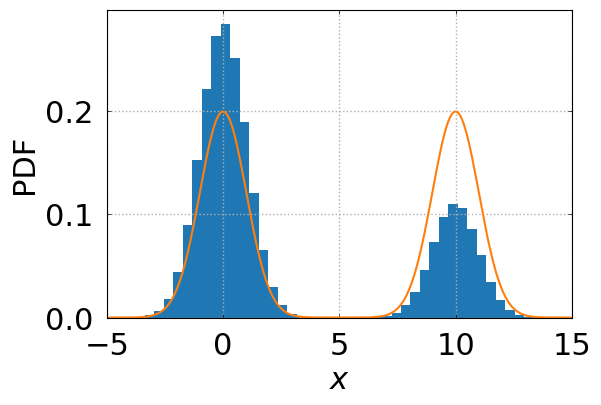

In [4]:
fig,ax = plt.subplots(ncols=1, nrows=1, figsize=(6,4))

xmin = -5
xmax = 15
x = np.linspace(xmin,xmax,500)

ax.hist(samples, bins=np.linspace(xmin,xmax,50), density=True)
ax.plot(x, np.exp(log_f(x, mu1))/np.sqrt(2*np.pi)/2)

ax.grid(True,linestyle=':',linewidth='1.')
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')
ax.tick_params('both',length=3,width=0.5,which='both',direction = 'in',pad=10)

ax.set_xlim(xmin,xmax)

ax.set_xlabel('$x$')
ax.set_ylabel('PDF')

Text(0, 0.5, '$x$')

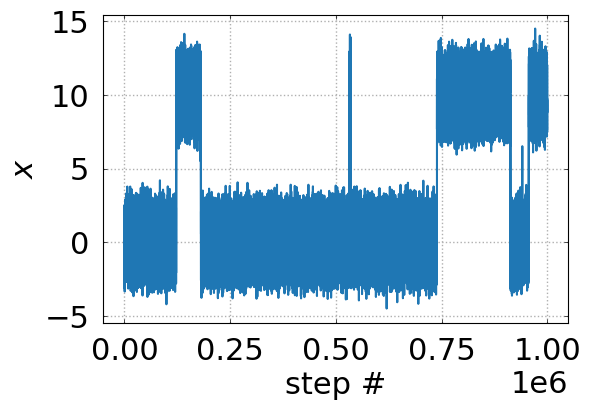

In [5]:
# Markov chain

fig,ax = plt.subplots(ncols=1, nrows=1, figsize=(6,4))

ax.plot(samples)

ax.grid(True,linestyle=':',linewidth='1.')
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')
ax.tick_params('both',length=3,width=0.5,which='both',direction = 'in',pad=10)


ax.set_xlabel('step #')
ax.set_ylabel('$x$')

<u>EXERCISE</u>

A possible remedy for PDFs like this is to use a random initialization for the initial position of the walker.

1. Choose `x0` randomly in some reasonable range. Run the sampling with the random initialization a few times. Combine the the outputs. Does the result look better than when `x0` was fixed?

2. (this part is a bit trickier; you can try it if you have some extra time). Optimize the procedure from part (1). Walkers with different random initial values can be evolved simultaneously. `x0` can be set to be a numpy array of random initial values, each of which is evolved in parallel. The trickiest part is the `if` statement which won't work for numpy array as is. It can be modified as follows:
   - the comparison is used to give an array of conditions (a boolean array of True/False);
   - the condition array is then applied to set new values for the walkers that satisfy the condition;
   - walkers that do not satisfy the condition are left as is;

<u>EXAMPLE (2D)</u>

An asymmetric Gaussian

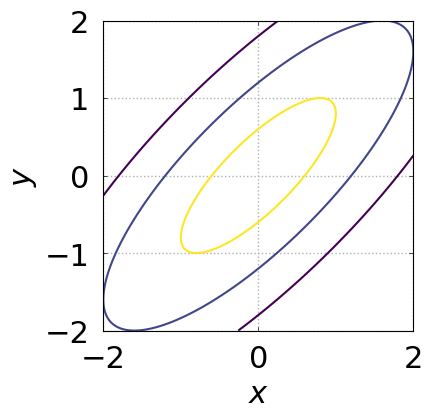

In [24]:
def logGaussian_2D(x,y, cov, means=[0.,0.]):
    
    inv_cov = np.linalg.inv(cov)
    dx = x-means[0]
    dy = y-means[1]
    
    return -0.5*(inv_cov[0,0]*dx**2 + 2*inv_cov[1,0]*dx*dy + inv_cov[1,1]*dy**2)

sigma_x = 1.
sigma_y = 1.
rho=0.8

cov = np.array([[sigma_x**2,rho*sigma_x*sigma_y],\
                 [rho*sigma_x*sigma_y, sigma_y**2]])


X = np.linspace(-2,2,1000)
Y = np.linspace(-2,2,1000)

X,Y = np.meshgrid(X,Y)
Z = np.exp(logGaussian_2D(X,Y, cov))

fig,ax = plt.subplots(ncols=1, nrows=1, figsize=(4,6))

ax.contour(X,Y,Z, levels=np.exp(-0.5*np.arange(3,0,-1)**2))


ax.grid(True,linestyle=':',linewidth='1.')
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')
ax.tick_params('both',length=3,width=0.5,which='both',direction = 'in',pad=10)

ax.set_aspect('equal')

ax.set_xlabel('$x$')
ax.set_ylabel('$y$');

In [25]:
sample_size = 10000

# covariance matrix for the proposal PDF, which is a 2D Gaussian
cov_proposal = np.array([[1.,0.],\
                         [0.,1.]])


theta_old = -1 + 2*np.random.random(2)
samples = [theta_old]

for i in range(sample_size):

    theta_new = np.random.multivariate_normal(theta_old, cov_proposal, size=1)[0]
    r = np.random.random()
    

    if logGaussian_2D(*theta_new, cov) - logGaussian_2D(*theta_old, cov) > np.log(r):
        theta_old = theta_new

    samples.append(theta_old)
    
samples = np.array(samples)

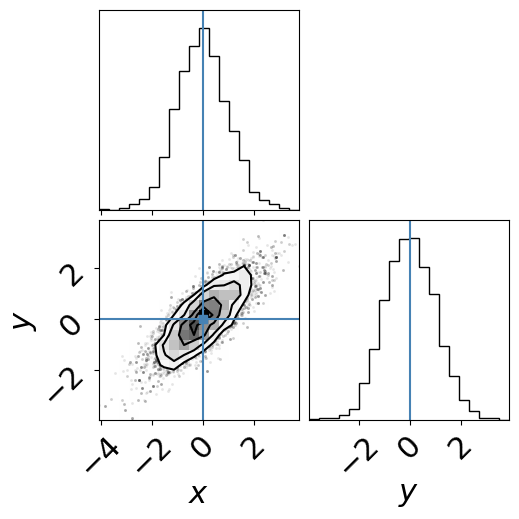

In [26]:
fig = corner.corner(
    samples, labels=['$x$', '$y$'], truths=[0,0]
);

<u>EXERCISE</u>

Experiment with the parameters of the proposal's covariance matrix. What can motivate that matrix in this particular problem of sampling from a skewed Gaussian? 

P.S. Here, we know the PDF we are sampling from, which is often not the case in real-life problems.

#### The Rosenbrock density

$$
f(\theta_1,\theta_2)\propto \exp\left\{-\frac{100\left(\theta_2-\theta_1^2\right)^2+(1-\theta_1)^2}{20}\right\}
$$

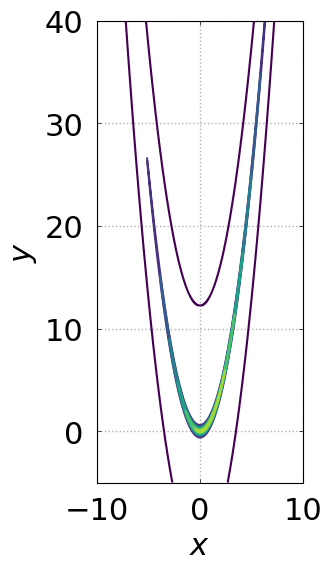

In [73]:
def logRosenbrock_plot(t1, t2):

    
    return -0.05*(100*(t2-t1**2)**2 + (1-t1)**2)

X = np.linspace(-10,10,1000)
Y = np.linspace(-5,40,1000)

X,Y = np.meshgrid(X,Y)
Z = np.exp(logRosenbrock_plot(X,Y))

fig,ax = plt.subplots(ncols=1, nrows=1, figsize=(4,6))

ax.contour(X,Y,Z)


ax.grid(True,linestyle=':',linewidth='1.')
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')
ax.tick_params('both',length=3,width=0.5,which='both',direction = 'in',pad=10)

ax.set_aspect('equal')

ax.set_xlabel('$x$')
ax.set_ylabel('$y$');

In [74]:
sample_size = 10000

# covariance matrix for the proposal PDF, which is a 2D Gaussian
cov_proposal = np.array([[1.,0.],\
                         [0.,1.]])


theta_old = -1 + 2*np.random.random(2)
samples = [theta_old]

for i in range(sample_size):

    theta_new = np.random.multivariate_normal(theta_old, cov_proposal, size=1)[0]
    r = np.random.random()
    

    if logRosenbrock(*theta_new) - logRosenbrock(*theta_old) > np.log(r):
        theta_old = theta_new

    samples.append(theta_old)
    
samples = np.array(samples)

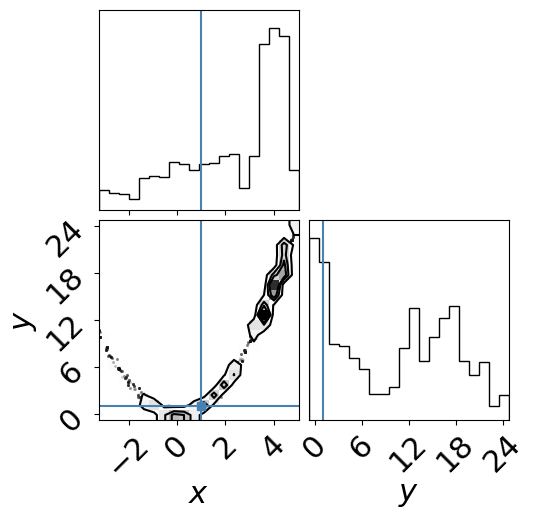

In [75]:
fig = corner.corner(
    samples, labels=['$x$', '$y$'], truths=[1,1]
);

<u>EXERCISE</u>

Experiment with the parameters of the proposal's covariance matrix and the number of steps to sample from the Rosenbrock density. Can you get a better sampling than above? 

### Loner walkers vs. Teamplayer walkers

Above we saw that there exist some PDFs for which the ordinary MH performs not so well. One of the remedies is to use random initializations for the walkers and then combine the outputs. But still, the walkers do not "talk" to each other. Consider two walkers which were initialized in separate domains of a distribution. Can we somehow make them exchange information about the domains that they are walking around? Yes, we can! Prescriptions for exchanging info among walkers are referred to as *moves*. The *emcee* package uses the so-called *stretch move*. We will not be implementing it ourselves, but just for reference, here it is.

1. To advance walker $X_k$:

- choose a walker $X_j$ at random;
- sample a random number $Z$ from an auxiliary distribution $g(z)$;
- the proposed position of the walker $X_k$: $Y=X_j + Z(X_k - X_j)$;

2. Repeat sequentially for all walkers.

The auxiliary distribution $g(z)$ must satisfy condition $g(z^{-1})=zg(z)$. For example,

$$
g(x)\propto \frac{1}{\sqrt{z}}\,, \qquad  z\in[1/a,a]\,,
$$
where $a\gtrsim 1$ (e.g. $a=2$).


### *emcee* package

In [76]:
def logRosenbrock(theta):
    
    t1,t2 = theta

    
    return -0.05*(100*(t2-t1**2)**2 + (1-t1)**2)


In [89]:
nwalkers = 16

pos = np.array([1 + np.random.randn(nwalkers) ,\
                -1 + np.random.randn(nwalkers)]).T
_, ndim = pos.shape

sampler = emcee.EnsembleSampler(
    nwalkers, ndim, logRosenbrock, args=()
)
sampler.run_mcmc(pos, 20000, progress=True);

100%|███████████████████████████████████| 20000/20000 [00:06<00:00, 3024.74it/s]


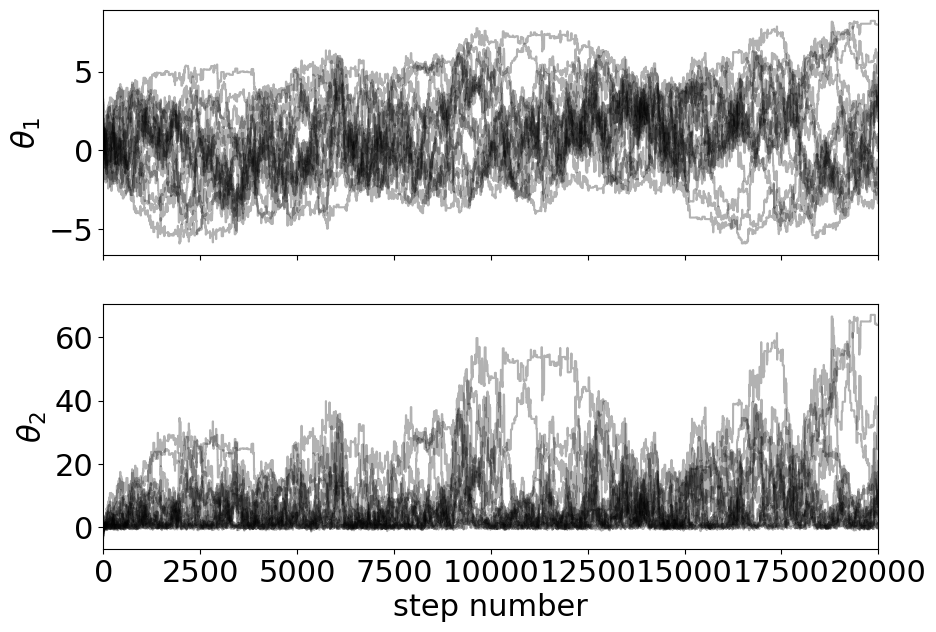

In [90]:
fig, axes = plt.subplots(ndim, figsize=(10, 7), sharex=True)
samples = sampler.get_chain()
labels = ["$\\theta_1$", "$\\theta_2$"]
for i in range(ndim):
    ax = axes[i]
    ax.plot(samples[:, :, i], "k", alpha=0.3)
    ax.set_xlim(0, len(samples))
    ax.set_ylabel(labels[i])
    #ax.yaxis.set_label_coords(-0.1, 0.5)

axes[-1].set_xlabel("step number");

(21216, 2)


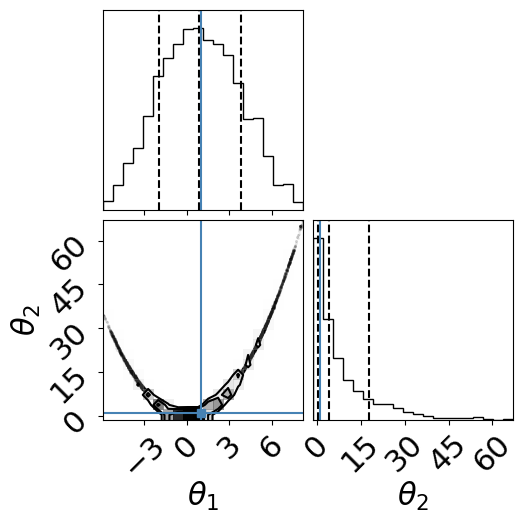

In [91]:
flat_samples = sampler.get_chain(discard=100, thin=15, flat=True)
print(flat_samples.shape)

fig = corner.corner(
    flat_samples, labels=labels, truths=[1,1], quantiles=[0.16, 0.5, 0.84]
);

<u>EXERCISE</u>

Use *emcee* to sample from the double 1D Gaussian and the skewed 2D Gaussian distribution.

### Straight-line fit with *emcee*

In [61]:
# our model for data

def f2(x,k,b):
    
    return k*x + b

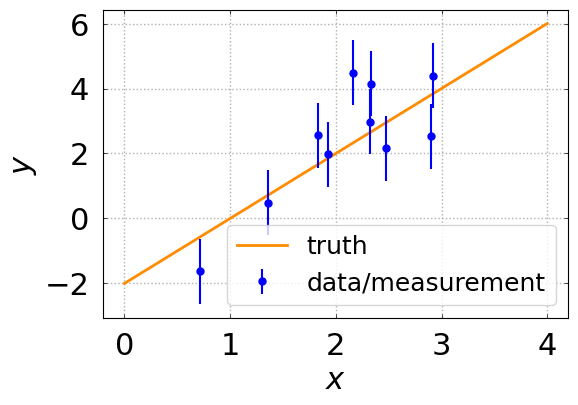

In [62]:
# generate data 

np.random.seed(13)   # a random seed to have the same data every time we run this code cell

k0 = 2  # a "true" value for k
b0 = -2

n_pts = 10
sigma = 1   # sigma for a Gaussian noise

x_data = 3*np.random.random(n_pts)   # x values for the "measurement"
y_true = f2(x_data,k0,b0)   # true y values
noise = sigma*np.random.randn(n_pts)
y_data = y_true + noise   # the data = true values + the noise
xx = np.linspace(0,4,500)
yy = f2(xx, k0, b0)

fig,ax = plt.subplots(ncols=1, nrows=1, figsize=(6,4))

ax.plot(xx,yy, c='darkorange', lw=2, label='truth')
ax.errorbar(x_data,y_data, yerr=sigma, fmt='b.', ms=10, label='data/measurement')

ax.grid(True,linestyle=':',linewidth='1.')
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')
ax.tick_params('both',length=3,width=0.5,which='both',direction = 'in',pad=10)

ax.set_xlabel('$x$')
ax.set_ylabel('$y$')

ax.legend()

In [67]:
def log_likelihood(theta, x_data, y_data):
    
    k,b = theta
    return -0.5*np.sum((k*x_data + b - y_data)**2)

def log_prior(theta):
    
    k,b = theta
    if 0.5<k<4 and -5<b<4:   # flat prior
        return 0.
    return -np.inf

def log_prob(theta, x_data, y_data):
    
    lp = log_prior(theta)
    if not np.isfinite(lp):
        return -np.inf
    return lp + log_likelihood(theta, x_data, y_data)

In [80]:
nwalkers = 128

pos = np.array([1 + np.random.randn(nwalkers) ,\
                1 + np.random.randn(nwalkers)]).T
_, ndim = pos.shape

sampler = emcee.EnsembleSampler(
    nwalkers, ndim, log_prob, args=(x_data,y_data)
)
sampler.run_mcmc(pos, 10000, progress=True);

100%|████████████████████████████████████| 10000/10000 [00:18<00:00, 544.03it/s]


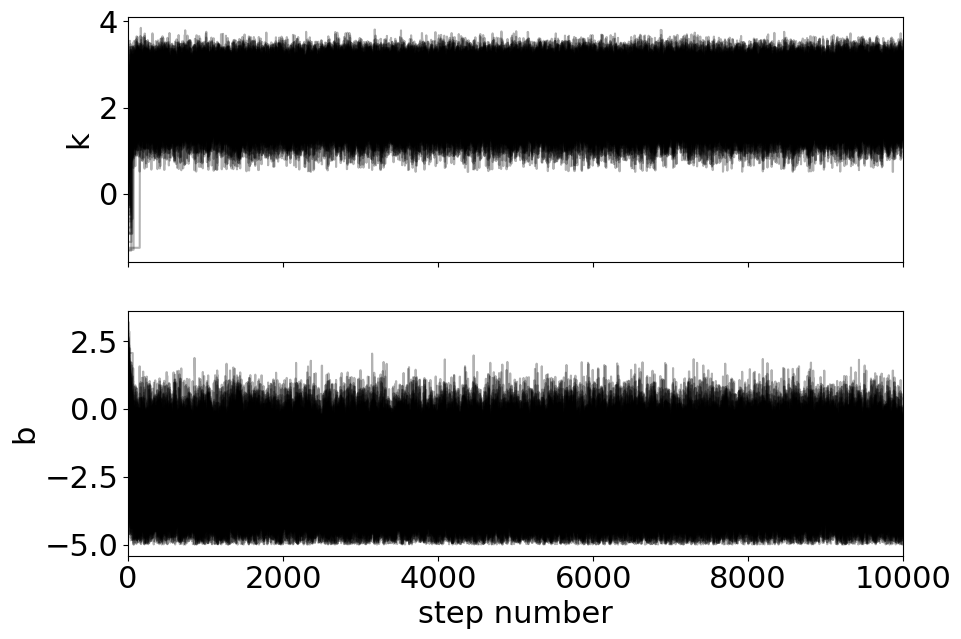

In [86]:
fig, axes = plt.subplots(ndim, figsize=(10, 7), sharex=True)
samples = sampler.get_chain()
labels = ["k", "b"]
for i in range(ndim):
    ax = axes[i]
    ax.plot(samples[:, :, i], "k", alpha=0.3)
    ax.set_xlim(0, len(samples))
    ax.set_ylabel(labels[i])
    #ax.yaxis.set_label_coords(-0.1, 0.5)

axes[-1].set_xlabel("step number");

(84480, 2)


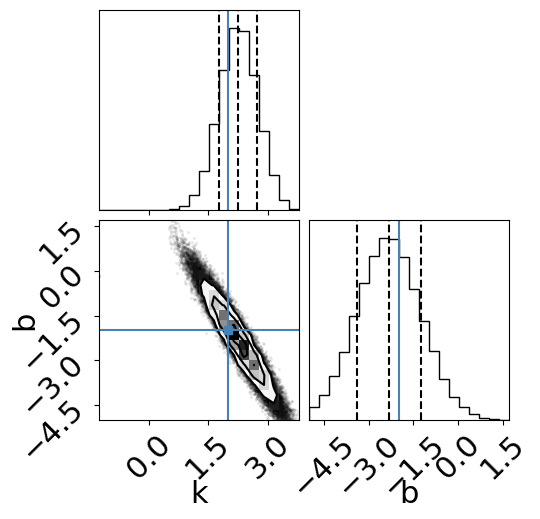

In [87]:
flat_samples = sampler.get_chain(discard=100, thin=15, flat=True)
print(flat_samples.shape)

fig = corner.corner(
    flat_samples, labels=labels, truths=[k0,b0], quantiles=[0.16, 0.5, 0.84]
);

In [88]:
from IPython.display import display, Math


for i in range(ndim):
    mcmc = np.percentile(flat_samples[:,i], [16, 50, 84])
    q = np.diff(mcmc)
    txt = "\mathrm{{{3}}} = {0:.3f}_{{-{1:.3f}}}^{{{2:.3f}}}"
    txt = txt.format(mcmc[1], q[0], q[1], labels[i])
    display(Math(txt))

<IPython.core.display.Math object>

<IPython.core.display.Math object>